# Data VZP: základní přehledy

Data hackathonu (`data_vzp/Rakhaton2026.csv.gz`): adresné pozvánky na mamografický screening 2020–2024.
Jen agregáty.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

BASE = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data_vzp").exists())
OUT = BASE / "outputs" / "vzp_basic_stats"
OUT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_rows", 100)

d = pd.read_csv(BASE / "data_vzp" / "Rakhaton2026.csv.gz", low_memory=False,
                usecols=["PERSON_ID", "INVITATION_DATE", "VZP_TERRITORIAL_AREA", "MONTHS_SINCE_LAST_SCREEN"])
print(f"{len(d):,} pozvánek · {d.PERSON_ID.nunique():,} žen")

1,344,556 pozvánek · 508,527 žen


## 1 · Počet žen podle územního pracoviště VZP

Unikátní ženy na pracoviště. Každá žena má v datech jediné pracoviště u všech svých pozvánek
(pravděpodobně aktuální přiřazení, ne stav k datu pozvánky), takže součet přes pracoviště je
roven počtu žen. Územní pracoviště není okres (viz popis dat).

pracovišť: 75 · součet žen přes pracoviště: 508,527 · žen u více pracovišť: 0 (0.0%)


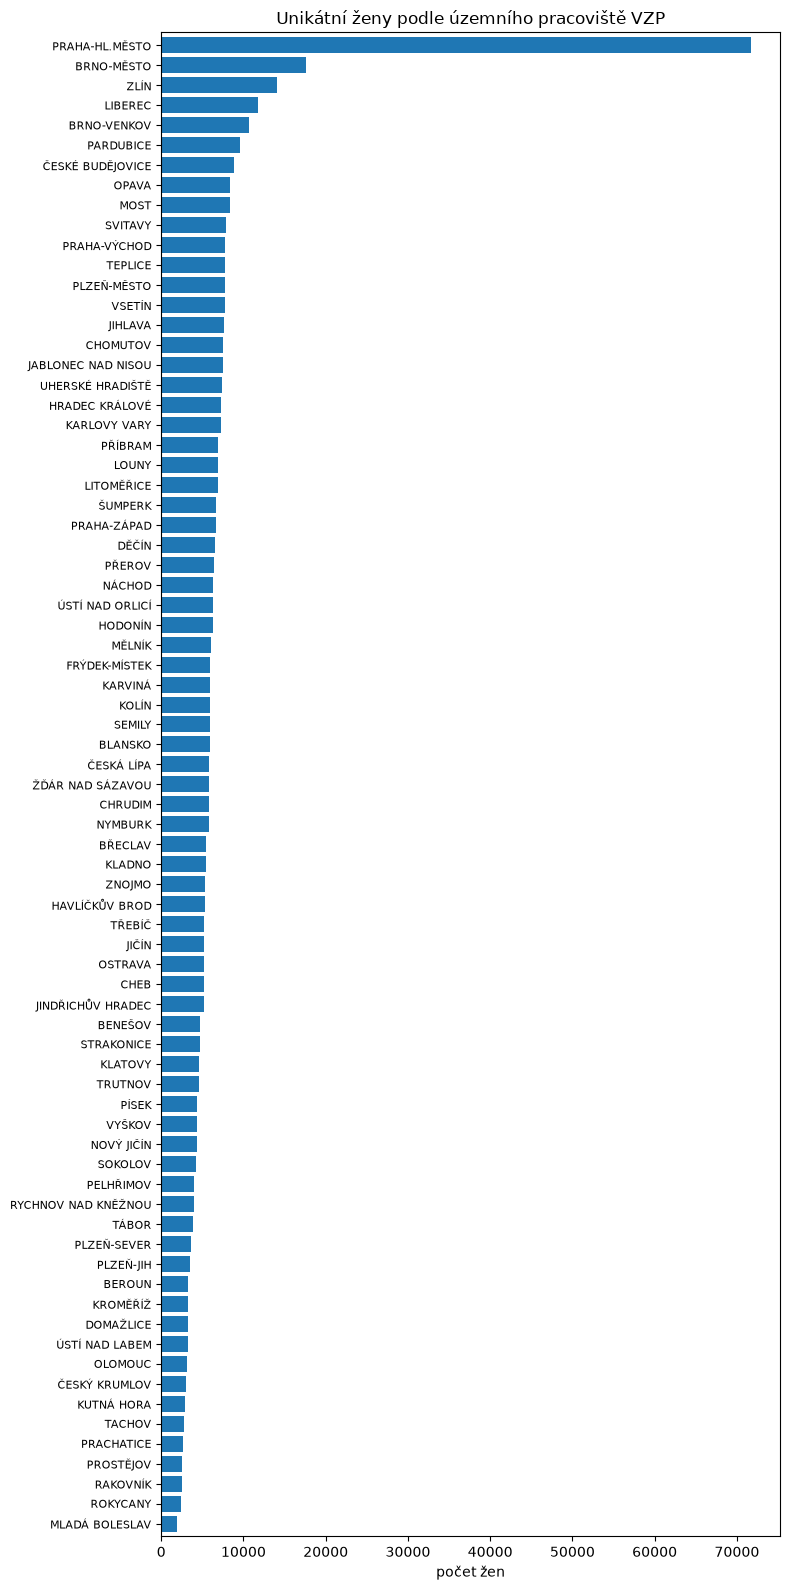

,žen,pozvánek,podíl žen
VZP_TERRITORIAL_AREA,,,
PRAHA-HL.MĚSTO,"71,656","193,569",14.1%
BRNO-MĚSTO,"17,655","46,643",3.5%
ZLÍN,"14,017","36,946",2.8%
LIBEREC,"11,793","29,522",2.3%
BRNO-VENKOV,"10,685","27,547",2.1%
PARDUBICE,"9,601","25,050",1.9%
ČESKÉ BUDĚJOVICE,"8,871","22,620",1.7%
OPAVA,"8,381","22,202",1.6%
MOST,"8,373","22,973",1.6%


In [2]:
UP = (d.groupby("VZP_TERRITORIAL_AREA")
        .agg(žen=("PERSON_ID", "nunique"), pozvánek=("PERSON_ID", "size"))
        .sort_values("žen", ascending=False))
UP["podíl žen"] = UP.žen / d.PERSON_ID.nunique()
UP.to_csv(OUT / "zeny_podle_pracoviste.csv")
n_up = d.groupby("PERSON_ID").VZP_TERRITORIAL_AREA.nunique()
print(f"pracovišť: {len(UP)} · součet žen přes pracoviště: {UP.žen.sum():,} · "
      f"žen u více pracovišť: {(n_up > 1).sum():,} ({(n_up > 1).mean():.1%})")

fig, ax = plt.subplots(figsize=(8, 16))
UP.žen[::-1].plot.barh(ax=ax, width=0.8)
ax.set_xlabel("počet žen"); ax.set_ylabel(""); ax.set_title("Unikátní ženy podle územního pracoviště VZP")
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout(); plt.savefig(OUT / "zeny_podle_pracoviste.png", dpi=120); plt.show()
UP.style.format({"žen": "{:,}", "pozvánek": "{:,}", "podíl žen": "{:.1%}"})

## 2 · Histogram měsíců od posledního screeningu

`MONTHS_SINCE_LAST_SCREEN` ke dni pozvánky, po měsících. Chybí u žen bez screeningu v posledních
5 letech. „Screening“ zde znamená kterýkoli z kódů štítků (včetně dovyšetření).

pozvánek s hodnotou: 244,270 (18.2%) · bez screeningu za 5 let: 1,100,286


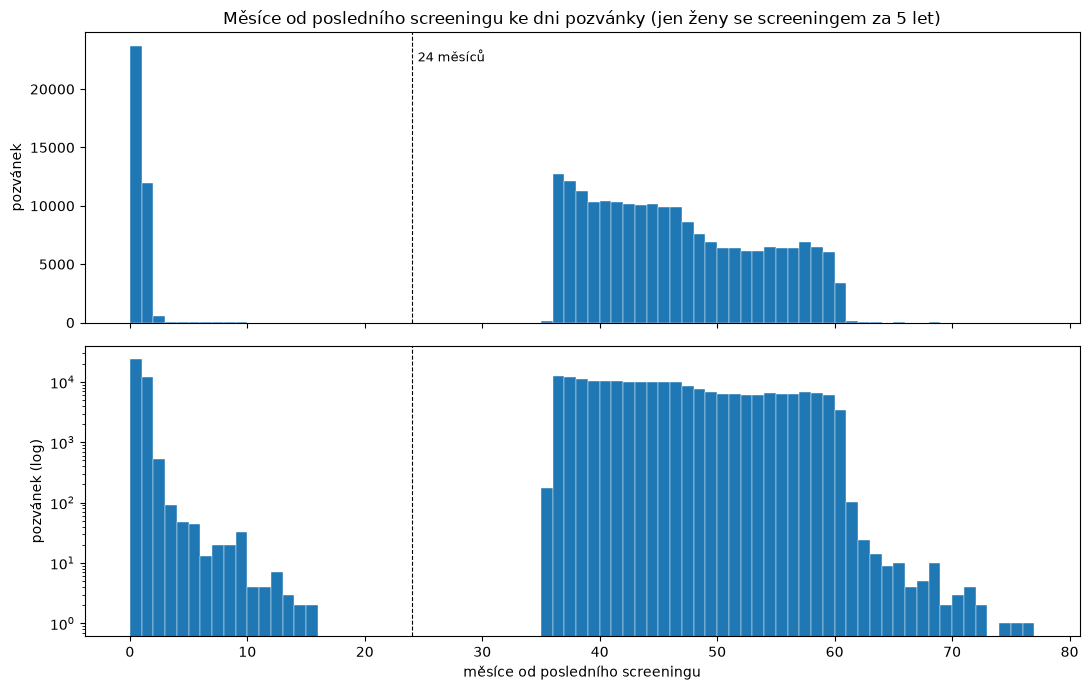

,pozvánek,podíl
MONTHS_SINCE_LAST_SCREEN,,
0–1,"35,673",14.6%
2–5,709,0.3%
6–23,108,0.0%
24–35,177,0.1%
36–48,"133,472",54.6%
49–60,"73,938",30.3%
61+,193,0.1%


In [3]:
m = d.MONTHS_SINCE_LAST_SCREEN
print(f"pozvánek s hodnotou: {m.notna().sum():,} ({m.notna().mean():.1%}) · bez screeningu za 5 let: {m.isna().sum():,}")

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
for ax, log in zip(axes, [False, True]):
    ax.hist(m.dropna(), bins=range(0, int(m.max()) + 2), color="C0", edgecolor="white", linewidth=0.3)
    ax.axvline(24, color="k", ls="--", lw=0.8)
    ax.set_ylabel("pozvánek" + (" (log)" if log else ""))
    if log:
        ax.set_yscale("log")
axes[0].text(24.5, axes[0].get_ylim()[1] * 0.9, "24 měsíců", fontsize=9)
axes[0].set_title("Měsíce od posledního screeningu ke dni pozvánky (jen ženy se screeningem za 5 let)")
axes[1].set_xlabel("měsíce od posledního screeningu")
plt.tight_layout(); plt.savefig(OUT / "mesice_od_posledniho_screeningu.png", dpi=120); plt.show()

pasma = pd.cut(m, [-1, 1, 5, 23, 35, 48, 60, 1000],
               labels=["0–1", "2–5", "6–23", "24–35", "36–48", "49–60", "61+"])
H = pasma.value_counts(sort=False).to_frame("pozvánek")
H["podíl"] = H.pozvánek / m.notna().sum()
H.to_csv(OUT / "mesice_od_posledniho_screeningu.csv")
H.style.format({"pozvánek": "{:,}", "podíl": "{:.1%}"})

**Čtení.** 98 % pozvánek do 2 let po screeningu odešlo 0–1 měsíc po něm: dopis se nejspíš minul se
screeningem, o kterém systém zvaní ještě nevěděl (zpoždění vykázání). Mezi 16 a 35 měsíci nejsou
skoro žádné pozvánky; od 36 měsíců jich je hodně. V praxi se tedy zve až po 3 letech bez
screeningu, ačkoli interval programu jsou 2 roky (ověřit u VZP: pravidlo programu, nebo výběr
dopisů 3, 4, 7, 8 v tomto extraktu?).